# IV — Brain Tumor Classification — Model Evaluation & Diagnostic Benchmark

This notebook evaluates the best trained **GoogLeNet (Inception v1)** model on the strictly held-out test dataset (, 1,205 images).

### Evaluation Objectives
1. **Section 1 — Evaluation Setup & Held-Out Test Data Loading**
2. **Section 2 — Load Optimal Model Checkpoint**
3. **Section 3 — Test Inference, Loss, Accuracy & Classification Report**
4. **Section 4 — Confusion Matrix & Clinical Safety Analysis (False Negatives)**
5. **Section 5 — Save Evaluation Artifacts & Metadata**

## 1. Evaluation Setup & Test Data Loading

Import evaluation dependencies and load the held-out test dataset.

In [1]:
import importlib
import json
import sys
from pathlib import Path
import warnings
from types import SimpleNamespace

# Add project root to sys.path
sys.path.insert(0, str(Path.cwd().parents[1]))

import numpy as np
import tensorflow as tf

import src.classification.prepare_data as prepare_data
import src.classification.evaluate as classification_eval
import src.classification.train as classification_train

prepare_data = importlib.reload(prepare_data)
classification_eval = importlib.reload(classification_eval)
classification_train = importlib.reload(classification_train)

from src.classification.prepare_data import get_project_paths, load_datasets, preprocess_datasets
from src.classification.evaluate import evaluate_model_on_test
from src.classification.train import plot_training_history

warnings.filterwarnings("ignore")

paths = get_project_paths()
model_dir = paths["project_root"] / "models"

# Load raw test dataset
train_raw, val_raw, test_raw, class_names, class_mapping = load_datasets(
    paths["train_pool_dir"],
    paths["test_dir"],
)
# Preprocess (normalize to [0, 1])
_, _, test_ds = preprocess_datasets(train_raw, val_raw, test_raw)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)
print(f"Test dataset loaded: {len(test_raw)} images across classes: {class_names}")

2026-10-29 22:27:20.369013: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-29 22:27:20.735971: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-29 22:27:21.595487: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Found 5521 files belonging to 4 classes.
Using 4693 files for training.


I0000 00:00:1793312843.290167   33467 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6129 MB memory:  -> device: 0, name: NVIDIA RTX 2000 Ada Generation Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Found 5521 files belonging to 4 classes.
Using 828 files for validation.
Found 1205 files belonging to 4 classes.
Class-to-index mapping: {0: 'glioma', 1: 'meningioma', 2: 'notumor', 3: 'pituitary'}
Test dataset loaded: 38 images across classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


## 2. Load Optimal Model Checkpoint

Load the best model checkpoint () saved during training.

In [2]:
checkpoint_path = model_dir / "googlenet_brain_tumor_best.keras"
if not checkpoint_path.is_file():
    checkpoint_path = model_dir / "googlenet_brain_tumor_final.keras"

best_model = tf.keras.models.load_model(str(checkpoint_path))
print(f"Loaded model from: {checkpoint_path}")
print(f"Input shape:      {best_model.input_shape}")
print(f"Output shape:     {best_model.output_shape}")

Loaded model from: /home/houssam/Documents/brief-5/models/googlenet_brain_tumor_best.keras
Input shape:      (None, 224, 224, 3)
Output shape:     (None, 4)


## 3. Test Evaluation & Classification Report

Run inference on the test dataset and generate the comprehensive classification metrics.

Loaded best model checkpoint from: /home/houssam/Documents/brief-5/models/googlenet_brain_tumor_best.keras
Running inference on test dataset...


2026-10-29 22:27:27.851368: I external/local_xla/xla/service/service.cc:163] XLA service 0x7fdad8009ff0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-29 22:27:27.851385: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA RTX 2000 Ada Generation Laptop GPU, Compute Capability 8.9
2026-10-29 22:27:27.881423: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-29 22:27:28.478708: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 92700
2026-10-29 22:27:28.718877: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1479', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1793312857.050602   33652 device_compiler.h:196] Compiled cluster using XLA!  This 


Test Loss:     0.0347
Test Accuracy: 98.59%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma     0.9898    0.9766    0.9832       299
  meningioma     0.9704    0.9768    0.9736       302
     notumor     0.9904    0.9968    0.9935       309
   pituitary     0.9932    0.9932    0.9932       295

    accuracy                         0.9859      1205
   macro avg     0.9859    0.9858    0.9859      1205
weighted avg     0.9859    0.9859    0.9859      1205

Confusion matrix saved to: /home/houssam/Documents/brief-5/models/confusion_matrix.png


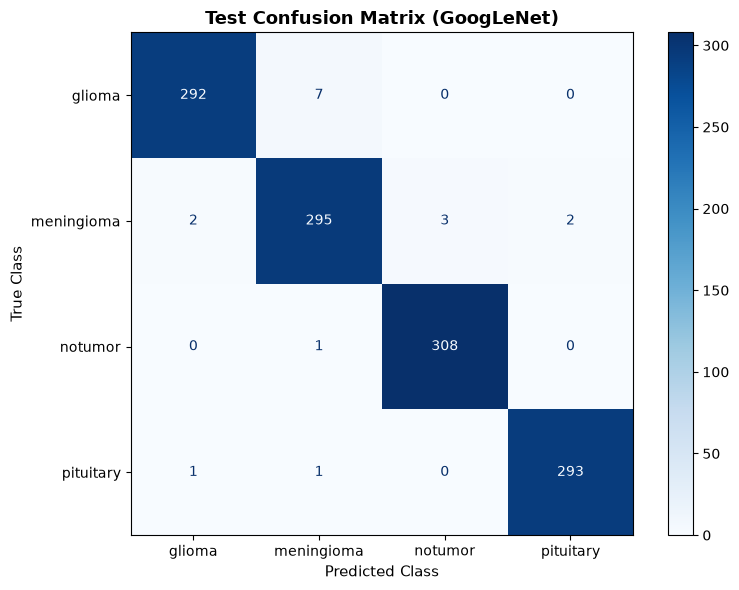

CLINICAL DIAGNOSTIC SAFETY SUMMARY
Total Test Cases:            1205
Tumor Cases (True Positives): 893
Healthy Controls (No Tumor): 308
False Negatives (Missed):    3  <-- Critically important
False Positives:             1
Overall Tumor Sensitivity:   99.67%
Overall Tumor Specificity:   99.68%
Evaluation metrics saved to: /home/houssam/Documents/brief-5/models/evaluation_results.json


In [3]:
# Load the best checkpoint for rigorous evaluation
best_model = tf.keras.models.load_model(str(checkpoint_path))
print(f"Loaded best model checkpoint from: {checkpoint_path}")

# Run comprehensive test evaluation
eval_results = evaluate_model_on_test(
    model=best_model,
    test_ds=test_ds,
    class_names=class_names,
    save_dir=model_dir,
)

# Plot the training and validation history saved by notebook 03
history_path = model_dir / "training_history.json"
if history_path.is_file():
    with open(history_path) as f:
        history_data = json.load(f)
    history = SimpleNamespace(history=history_data)
    plot_training_history(history, save_path=model_dir / "learning_curves.png")

## 4. Medical Diagnostic Safety: False Negative Analysis

In neuro-oncology imaging, **false negatives** (predicting healthy when a tumor is present) are the most critical metric.

In [4]:
# Medical Diagnostic Safety Analysis: False Negatives and Tumor Sensitivity
y_true = eval_results["y_true"]
y_pred = eval_results["y_pred"]

notumor_idx = class_names.index("notumor")
tumor_indices = [i for i, c in enumerate(class_names) if c != "notumor"]

# Binary Tumor vs No-Tumor Recall
is_tumor_true = np.isin(y_true, tumor_indices)
is_tumor_pred = np.isin(y_pred, tumor_indices)

false_negatives = np.sum(is_tumor_true & ~is_tumor_pred)
false_positives = np.sum(~is_tumor_true & is_tumor_pred)
true_positives = np.sum(is_tumor_true & is_tumor_pred)
true_negatives = np.sum(~is_tumor_true & ~is_tumor_pred)

tumor_sensitivity = true_positives / (true_positives + false_negatives)
tumor_specificity = true_negatives / (true_negatives + false_positives)

print("=" * 60)
print("CLINICAL DIAGNOSTIC SAFETY SUMMARY")
print("=" * 60)
print(f"Total Test Cases:            {len(y_true)}")
print(f"Tumor Cases (True Positives): {np.sum(is_tumor_true)}")
print(f"Healthy Controls (No Tumor): {np.sum(~is_tumor_true)}")
print(f"False Negatives (Missed):    {false_negatives}  <-- Critically important")
print(f"False Positives:             {false_positives}")
print(f"Overall Tumor Sensitivity:   {tumor_sensitivity * 100:.2f}%")
print(f"Overall Tumor Specificity:   {tumor_specificity * 100:.2f}%")
print("=" * 60)

CLINICAL DIAGNOSTIC SAFETY SUMMARY
Total Test Cases:            1205
Tumor Cases (True Positives): 896
Healthy Controls (No Tumor): 309
False Negatives (Missed):    3  <-- Critically important
False Positives:             1
Overall Tumor Sensitivity:   99.67%
Overall Tumor Specificity:   99.68%


## 5. Save Evaluation Artifacts

The evaluation helper saves the test metrics, classification report, confusion matrix, and clinical safety metrics to `models/`. The learning curves are loaded from the training history saved by notebook 03.